In [9]:
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from ml.data_io import iter_signals_and_targets
from ml.features import add_epoch_drift, build_feature_df
from ml.model import cross_validate_xgboost


In [ ]:
@dataclass
class Config:
    bundle_dir: Path = Path("data")
    sf: int = 100  # sampling rate
    samples_per_epoch: int = 30 * 100  # 30s epochs
    stage_names: list[str] = field(default_factory=lambda: ["Wake", "N1", "N2", "N3", "REM"])
    # Feature params
    load_precomputed_features: bool = False
    bands: dict[str, tuple[float, float]] = field(
        default_factory=lambda: {
            "slow_delta": (0.5, 2),
            "delta": (2, 4),
            "theta": (4, 8),
            "alpha": (8, 12),
            "sigma": (12, 15),
            "beta": (15, 30),
        },
    )
    add_epoch_drift_window: int = 2
    add_epoch_drift_symmetric: bool = True
    # model params
    num_classes: int = 5
    eta: float = 0.03
    max_depth: int = 4
    subsample: float = 0.8
    colsample_bytree: float = 0.8
    num_boost_round: int = 500
    seed: int = 42
    smoothing_window: int = 1
    n_jobs: int = 4
    gamma: float = 1.5
    # decoding
    decoder: str = "hmm"  # options: "argmax", "smooth", "hmm"
    hmm_alpha: float = 1.0
    # cross-validation params
    cv_n_splits: int = 5

# Données et Features

In [3]:
config = Config(bundle_dir = Path("../data"))

In [4]:
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")

In [5]:
df_train = build_feature_df(raw_train_data, with_labels=True, config=config)
df_train = add_epoch_drift(
    df_train,
    window=config.add_epoch_drift_window,
    symmetric=config.add_epoch_drift_symmetric,
)

In [6]:
df_train

,patient_id,epoch_idx,identifier,mean,std,ptp,slow_delta,delta,theta,alpha,...,sigma_burst_frac,spec_entropy,log_delta_theta,log_alpha_beta,theta_dominance,beta_silence,label,epoch_drift_prev,epoch_drift_next,epoch_drift_mean
0,0,0,0,-0.002056,0.281659,1.955991,-4.520100,-5.970237,-5.368990,-2.903019,...,0.036200,3.710827,-0.601247,2.759551,-2.527367,-0.293580,0,0.000000,0.011959,0.005980
1,0,1,1,0.000493,0.262859,1.850865,-4.547810,-6.007101,-5.630204,-3.162292,...,0.035133,3.624036,-0.376896,2.752184,-2.529749,-0.284272,0,0.000000,0.010574,0.005287
2,0,2,2,0.000763,0.261666,1.680616,-4.925597,-5.917502,-5.565328,-3.336606,...,0.045067,3.490024,-0.352174,2.774341,-2.289244,-0.545619,0,0.003025,0.012279,0.007652
3,0,3,3,-0.001942,0.241289,1.666237,-5.221362,-6.146073,-5.819474,-3.343122,...,0.042133,3.488085,-0.326599,2.767822,-2.537258,-0.291470,0,0.011959,0.013904,0.012932
4,0,4,4,0.002725,0.240692,1.793912,-4.713387,-5.844990,-5.661986,-3.598101,...,0.044467,3.551208,-0.183004,2.557121,-2.138555,-0.493236,0,0.010574,0.017791,0.014183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7428,7,977,70977,0.000615,0.570573,6.274639,-2.059146,-3.144259,-3.555673,-3.289054,...,0.037200,3.962634,0.411414,0.053261,-0.933490,0.213357,0,0.454698,0.251684,0.353191
7429,7,978,70978,0.000891,0.985119,10.758858,-1.192349,-1.859668,-2.987002,-2.994042,...,0.040200,3.612344,1.127334,0.038533,-0.667026,-0.045573,0,0.291540,0.193473,0.242507
7430,7,979,70979,0.000443,3.134613,30.283478,1.515543,-0.234421,-1.476548,-1.790474,...,0.050933,2.745929,1.242127,-0.435103,-0.620253,0.121177,0,0.084006,0.109842,0.096924
7431,7,980,70980,-0.016104,2.287064,20.639336,0.571515,-0.591914,-1.732648,-2.285462,...,0.041400,2.993818,1.140734,-0.299185,-0.301073,-0.253629,0,0.251684,0.092133,0.171908


# Cross-Validation

In [7]:
X = df_train.drop(columns=["label", "identifier", "patient_id", "epoch_idx"])
y = df_train["label"]
groups = df_train["patient_id"].to_numpy()

print("Starting cross-validation...")
cv_scores = cross_validate_xgboost(X, y, df_meta=df_train, groups=groups, config=config)

Starting cross-validation...

--- Fold 1/5 ---


Macro-F1: 0.7493
              precision    recall  f1-score   support

        Wake      0.956     0.918     0.937       330
          N1      0.345     0.413     0.376        46
          N2      0.817     0.901     0.857       332
          N3      0.897     1.000     0.946       175
         REM      0.833     0.508     0.631       128

    accuracy                          0.852      1011
   macro avg      0.770     0.748     0.749      1011
weighted avg      0.857     0.852     0.848      1011


--- Fold 2/5 ---
Macro-F1: 0.6640
              precision    recall  f1-score   support

        Wake      0.911     0.548     0.685        93
          N1      0.474     0.714     0.570        63
          N2      0.622     0.922     0.743       395
          N3      0.982     0.509     0.671       212
         REM      0.840     0.533     0.652       227

    accuracy                          0.696       990
   macro avg      0.766     0.645     0.664       990
weighted avg      0.767  

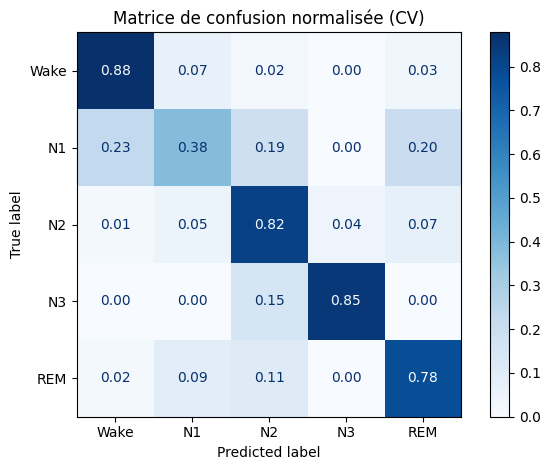

In [10]:
all_y_true = np.concatenate([f["y_true"] for f in cv_scores["folds"]])
all_y_pred = np.concatenate([f["y_pred"] for f in cv_scores["folds"]])

cm = confusion_matrix(all_y_true, all_y_pred, normalize="true")

disp = ConfusionMatrixDisplay(
    cm,
    display_labels=config.stage_names,
)

disp.plot(cmap="Blues", values_format=".2f")
plt.title("Matrice de confusion normalisée (CV)")
plt.tight_layout()


In [35]:
cv_scores["folds"][0]["patient_id"]

array([1, 1, 1, ..., 1, 1, 1], shape=(1011,))

In [39]:
def build_hypnogram(y, epoch_idx):
    order = np.argsort(epoch_idx)
    return y[order]

def plot_hypnogram(ax, gt, pred, stage_names, title):
    t = np.arange(len(gt))

    ax.step(t, gt, where="post", label="Ground truth", linewidth=2)
    ax.step(t, pred, where="post", label="Prediction", linewidth=2, alpha=0.85)

    ax.set_yticks(range(len(stage_names)))
    ax.set_yticklabels(stage_names)
    ax.set_ylim(-0.5, len(stage_names) - 0.5)

    ax.set_xlabel("Epochs")
    ax.set_ylabel("Sleep stage")
    ax.set_title(title)

    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", frameon=False)

def plot_hypnograms_one_per_fold(cv_scores, stage_names):
    n_folds = len(cv_scores["folds"])

    fig, axes = plt.subplots(
        n_folds, 1,
        figsize=(14, 2.2 * n_folds),
        sharex=False
    )

    if n_folds == 1:
        axes = [axes]

    for ax, fold_data in zip(axes, cv_scores["folds"]):
        # pick ONE patient from this fold
        pid = np.unique(fold_data["patient_id"])[0]
        mask = fold_data["patient_id"] == pid

        gt = build_hypnogram(
            fold_data["y_true"][mask],
            fold_data["epoch_idx"][mask],
        )
        pred = build_hypnogram(
            fold_data["y_pred"][mask],
            fold_data["epoch_idx"][mask],
        )

        plot_hypnogram(
            ax,
            gt,
            pred,
            stage_names,
            title=f"Fold {fold_data['fold']+1} — Patient {pid}",
        )

    # one legend for the whole figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", frameon=False)

    axes[-1].set_xlabel("Epochs")
    plt.tight_layout()


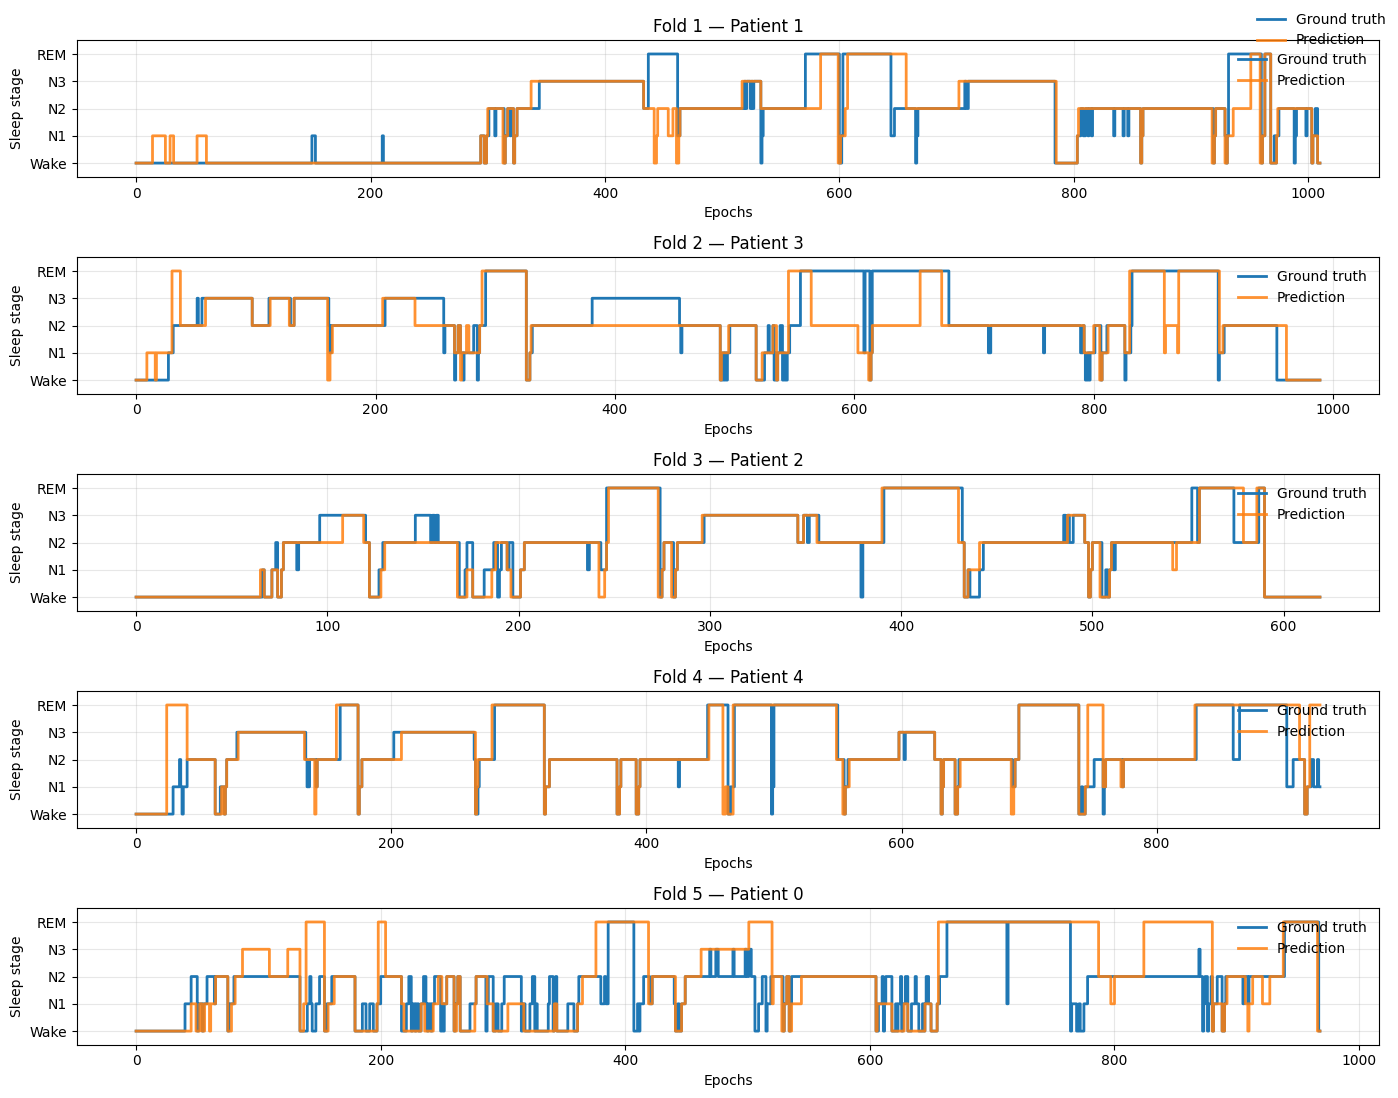

In [40]:
plot_hypnograms_one_per_fold(
    cv_scores,
    stage_names=config.stage_names,
)
